# Primary strategy experiment, reproduced with `quant_forge.strategies`

This notebook reruns the experiment of `primary_strategies.ipynb` using the library instead of the in-notebook
`strategy_events` function. Same input data, same selected strategy (`strategy_432_btc`, i.e.
`donchian_breakout_continuation`), same parameters (`fee_bps=5`, everything else at its default: `next_open`
execution, 95 % of equity, no shorts), same ML evaluation. The last cell checks the numbers against the outputs
stored in the original notebook.

Requires the library to be installed (`pip install -e .` from the project root, plus the `research` extra for
pyarrow / scikit-learn / catboost / matplotlib).

## Data (unchanged from the original notebook)

In [612]:
from pathlib import Path
import pandas as pd
import quant_forge.strategies as qs



def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
volume_100 = pd.read_parquet(DATASETS_DIR / "BTCUSDT_spot_time_4h_4h_20210901-20260901_e751456d/time.parquet")

In [613]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

In [614]:
"""Features for RSI cross-above meta-labeling.

Usage: df_features = add_rsi_context_features(df, rsi_length=14, rsi_level=70)
All windows are bars, not calendar time. Use at the signal-bar decision time.
Only NumPy and pandas required. No stationarity or predictive-skill guarantee.
No fractional differentiation or fitted transformations are performed here.
EMA uses adjust=False; RSI/ATR/ADX use SMA-seeded Wilder averages.
Invalid bars and segment/sequence/overlap breaks reset indicator history.
Zero-denominator ratios remain NaN, except flat RSI=50 and flat ADX/DI=0.
Existing added_/strategy_ output columns are replaced on a repeated call.
"""

import numpy as np
import pandas as pd


def add_rsi_context_features(df, rsi_length=14, rsi_level=70.0):
    """Decision-time features; lookbacks/lags are in bars, within valid segments."""
    required = {
        "open", "high", "low", "close", "series_id", "segment_id",
        "bar_seq", "bar_start_us", "bar_end_us", "complete",
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if not isinstance(rsi_length, int) or isinstance(rsi_length, bool) or rsi_length < 2:
        raise ValueError("rsi_length must be an integer >= 2")
    if not 0 < rsi_level < 100:
        raise ValueError("rsi_level must be in (0, 100)")
    if df[["series_id", "segment_id"]].isna().any().any():
        raise ValueError("Missing series_id or segment_id")

    def rma(s, n):
        # Wilder: SMA seed of first n consecutive finite observations.
        a = s.to_numpy(dtype=float)
        out = np.full(len(a), np.nan)
        finite = np.flatnonzero(np.isfinite(a))
        if not len(finite):
            return pd.Series(out, index=s.index)
        first = finite[0]
        if len(a) < first + n:
            return pd.Series(out, index=s.index)
        if not np.isfinite(a[first:]).all():
            raise ValueError("Unexpected internal gap in a valid segment")
        k = first + n - 1
        out[k] = a[first:k + 1].mean()
        for j in range(k + 1, len(a)):
            out[j] = out[j - 1] + (a[j] - out[j - 1]) / n
        return pd.Series(out, index=s.index)

    def rsi(c, n):
        change = c.diff()
        gain = rma(change.clip(lower=0), n)
        loss = rma((-change).clip(lower=0), n)
        value = 100 * gain / (gain + loss)
        return value.mask((gain == 0) & (loss == 0), 50.0)

    def div(a, b):
        return a / b.where(b > 0)

    def segment_features(g):
        o, h, l, c = [g[k].astype(float).reset_index(drop=True)
                      for k in ("open", "high", "low", "close")]
        f = {}
        r = rsi(c, rsi_length)
        previous = r.shift(1)
        f["strategy_rsi_overshoot"] = (r - rsi_level) / 100
        for lag in (1, 3, 5):
            f[f"strategy_rsi_slope_{lag}"] = r.diff(lag) / (100 * lag)
        f["strategy_rsi_curvature_3"] = (r - 2*r.shift(3) + r.shift(6)) / 900
        f["strategy_rsi_prior_range_10"] = (
            previous.rolling(10).max() - previous.rolling(10).min()
        ) / 100
        above = (r > rsi_level).astype(float).where(r.notna())
        f["strategy_rsi_prior_above_frac_20"] = above.shift(1).rolling(20).mean()
        cross = (((r > rsi_level) & (previous <= rsi_level)) |
                 ((r < rsi_level) & (previous >= rsi_level)))
        cross = cross.astype(float).where(r.notna() & previous.notna())
        f["strategy_rsi_prior_cross_rate_20"] = cross.shift(1).rolling(20).mean()

        run = np.full(len(r), np.nan)
        count = 0
        for i, value in enumerate(r):
            if not np.isfinite(value):
                count = 0
                continue
            count = min(count + 1, 50) if value <= rsi_level else 0
            run[i] = count / 50
        f["strategy_rsi_prior_below_run_50"] = pd.Series(run).shift(1)
        f["strategy_rsi_fast_slow_gap"] = (rsi(c, 7) - rsi(c, 28)) / 100

        tr = pd.concat([h-l, (h-c.shift()).abs(), (l-c.shift()).abs()], axis=1).max(axis=1)
        tr.iloc[0] = np.nan
        atr = rma(tr, 14)
        ema = {n: c.ewm(span=n, adjust=False, min_periods=n).mean()
               for n in (9, 12, 20, 26, 50, 200)}
        for n in (20, 50, 200):
            f[f"added_ema_{n}_distance_atr"] = div(c-ema[n], atr)
            f[f"added_ema_{n}_slope_5_atr"] = div(ema[n].diff(5), 5*atr)
        f["added_ema_20_50_gap_atr"] = div(ema[20]-ema[50], atr)
        for n in (10, 20):
            f[f"added_directional_efficiency_{n}"] = div(
                c.diff(n), c.diff().abs().rolling(n).sum()
            )

        up, down = h.diff(), -l.diff()
        plus_dm = up.where((up > down) & (up > 0), 0.0)
        minus_dm = down.where((down > up) & (down > 0), 0.0)
        plus_dm.iloc[0] = minus_dm.iloc[0] = np.nan
        plus_di, minus_di = 100*div(rma(plus_dm, 14), atr), 100*div(rma(minus_dm, 14), atr)
        di_sum = plus_di + minus_di
        balance = div(plus_di-minus_di, di_sum)
        balance = balance.mask(di_sum.eq(0), 0.0)
        # Flat periods: directional strength is defined as zero.
        balance = balance.mask(atr.eq(0), 0.0)
        f["added_di_balance_14"] = balance
        f["added_adx_14_norm"] = rma(balance.abs(), 14)

        macd = ema[12] - ema[26]
        signal = macd.ewm(span=9, adjust=False, min_periods=9).mean()
        f["added_macd_12_26_atr"] = div(macd, atr)
        f["added_macd_hist_12_26_9_atr"] = div(macd-signal, atr)
        for n in (20, 50):
            upper = h.shift(1).rolling(n).max()
            f[f"added_donchian_upper_distance_{n}_atr"] = div(c-upper, atr)
        mean20, std20 = c.rolling(20).mean(), c.rolling(20).std(ddof=0)
        f["added_bb_position_20"] = div(c-mean20, 2*std20)
        f["added_bb_width_rel_20"] = div(4*std20, mean20)
        f["added_runup_from_low_20_atr"] = div(c-l.shift(1).rolling(20).min(), atr)

        f["added_candle_body_fraction"] = div(c-o, h-l)
        f["added_upper_wick_fraction"] = div(h-pd.concat([o, c], axis=1).max(axis=1), h-l)
        f["added_bar_range_prev_atr"] = div(h-l, atr.shift(1))
        logret = np.log(c).diff()
        f["added_return_vol_ratio_5_20"] = div(
            logret.rolling(5).std(ddof=0), logret.rolling(20).std(ddof=0)
        )
        for source, name in (
            ("trade_intensity_per_s", "added_trade_intensity_log_rel_20"),
            ("bar_duration_s", "added_duration_log_rel_20"),
        ):
            if source in g:
                s = pd.to_numeric(g[source], errors="coerce").reset_index(drop=True)
                s = s.where(np.isfinite(s) & (s > 0))
                f[name] = np.log(div(s, s.shift(1).rolling(20).median()))
        return pd.DataFrame(f).replace([np.inf, -np.inf], np.nan)

    output = {}
    # Positional indexing preserves the original order, including interleaved series.
    for positions in df.groupby("series_id", sort=False).indices.values():
        g = df.iloc[positions].reset_index(drop=True)
        if not g["bar_start_us"].is_monotonic_increasing:
            raise ValueError("Sort each series chronologically before calling this function")
        prices = g[["open", "high", "low", "close"]].astype(float)
        valid = (
            np.isfinite(prices).all(axis=1) & prices.gt(0).all(axis=1)
            & g["complete"].eq(True)
            & g["high"].ge(g[["open", "close", "low"]].max(axis=1))
            & g["low"].le(g[["open", "close", "high"]].min(axis=1))
            & np.isfinite(g["bar_start_us"]) & np.isfinite(g["bar_end_us"])
            & g["bar_end_us"].ge(g["bar_start_us"])
            & g["bar_seq"].notna()
        )
        breaks = (
            g["segment_id"].ne(g["segment_id"].shift())
            | g["bar_seq"].diff().ne(1)
            | g["bar_start_us"].diff().le(0)
            | g["bar_start_us"].lt(g["bar_end_us"].shift())
            | ~valid | ~valid.shift(fill_value=False)
        )
        for _, part in g.groupby(breaks.cumsum(), sort=False):
            local = part.index.to_numpy()
            if not valid.iloc[local].all():
                continue
            features = segment_features(part)
            for name in features:
                if name not in output:
                    output[name] = np.full(len(df), np.nan)
                output[name][positions[local]] = features[name].to_numpy()
    result = df.copy()
    for name, values in output.items():
        result[name] = values
    return result

df = add_rsi_context_features(df)

In [615]:
train = df[df.index<'2024']
holdout = df[df.index>='2024']
# As in the original notebook, `train`/`holdout` are defined but the strategy below runs on the FULL `df`.

In [616]:
list(train.columns)

['bar_id',
 'series_id',
 'bar_type',
 'bar_seq',
 'segment_id',
 'bar_start_us',
 'bar_end_us',
 'first_trade_ts_us',
 'last_trade_ts_us',
 'first_trade_id',
 'last_trade_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'notional_usdt',
 'n_trades',
 'n_messages',
 'threshold_frozen',
 'complete',
 'bar_status',
 'bar_available_us',
 'decision_time_us',
 'bar_provenance',
 'bar_start',
 'bar_end',
 'bar_available',
 'decision_time',
 'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
 'ret_5min',
 'ret_5min_ref_age_s',
 'ret_1h',
 'ret_1h_ref_age_s',
 'ret_4h',
 'ret_4h_ref_age_s',
 'ret_1d',
 'ret_1d_ref_age_s',
 'ret_7d',
 'ret_7d_ref_age_s',
 'ret_30d',
 'ret_30d_ref_age_s',
 'rv_1h',
 'rvol_1h',
 'rvol_ann_1h',
 'rv_1d',
 'rvol_1d',
 'rvol_ann_1d',
 'rv_7d',
 'rvol_7d',
 'rvol_ann_7d',
 'rv_30d',
 'rvol_30d',
 'rvol_ann_30d',
 'rv_bars_20',
 'rv_bars_100',
 'bar_duration_s',
 'trade_span_s',
 'avg_trade_size',
 'trade_intensity_per_s',
 'volume_per_s',
 'notional_per_s',
 'aggr_buy_

## The strategy, as the library documents it

Every strategy exposes an inspectable specification: input columns (with timestamp rules), indicators, rules,
parameters, warm-up and invalid-data handling, and which features are required by the rules versus optional for ML.

In [617]:
print(qs.Strategies.DONCHIAN_BREAKOUT_CONTINUATION.spec.describe())

donchian_breakout_continuation - Strategy 432 BTC - Donchian breakout continuation
Enter on a close beyond the prior-bars Donchian channel confirmed by ADX, trend EMA and a minimum ATR-sized breakout; exit on a close back through the opposite channel edge or after hold_bars.
source: reference notebook primary_strategies.ipynb, strategy 'donchian_breakout_continuation' / 'strategy_432_btc' (Pine v6)
aliases: strategy_432_btc
inputs:
  - open (required, ohlc): bar open
  - high (required, ohlc): bar high
  - low (required, ohlc): bar low
  - close (required, ohlc): bar close
  - bar_start_us (required, timestamp): bar start, integer microseconds since UTC epoch; strictly increasing
  - bar_end_us (required, timestamp): bar end, integer microseconds >= bar_start_us
  - first_trade_ts_us (optional, timestamp): first trade of the bar; fill time of next_open orders [absent -> bar_start_us]
  - bar_available_us (optional, timestamp): when the bar became available [absent -> bar_end_us]
  - de

## Run the strategy

Original call: `df = strategy_events(df, strategy="strategy_432_btc", fee_bps=5)`.

The result is structured (candidate events, decision-time features, trades, diagnostics, metadata) and the input
frame is not modified or copied into the result. The bar-level columns the original notebook fed to its models are
requested explicitly through `context_columns`; they are copied **from the signal bar only** (the caller asserts they
are known at decision time).

In [618]:
ML_BAR_FEATURES = [
    "aggr_imbalance_volume",
    "spread_bps",
    "depth_imbalance_10bps",
    "depth_imbalance_25bps",
    "funding_rate_last",
    "basis_mark_index_1m",

    # Geometria RSI
    "strategy_rsi_overshoot",
    "strategy_rsi_slope_1",
    "strategy_rsi_slope_3",
    "strategy_rsi_slope_5",
    "strategy_rsi_curvature_3",
    "strategy_rsi_prior_range_10",
    "strategy_rsi_prior_above_frac_20",
    "strategy_rsi_prior_cross_rate_20",
    "strategy_rsi_prior_below_run_50",
    "strategy_rsi_fast_slow_gap",

    # Distanțe și pante EMA normalizate cu ATR
    "added_ema_20_distance_atr",
    "added_ema_20_slope_5_atr",
    "added_ema_50_distance_atr",
    "added_ema_50_slope_5_atr",
    "added_ema_200_distance_atr",
    "added_ema_200_slope_5_atr",
    "added_ema_20_50_gap_atr",

    # Persistența și forța trendului
    "added_directional_efficiency_10",
    "added_directional_efficiency_20",
    "added_di_balance_14",
    "added_adx_14_norm",

    # MACD normalizat cu ATR
    "added_macd_12_26_atr",
    "added_macd_hist_12_26_9_atr",

    # Breakout, Bollinger și extensia mișcării
    "added_donchian_upper_distance_20_atr",
    "added_donchian_upper_distance_50_atr",
    "added_bb_position_20",
    "added_bb_width_rel_20",
    "added_runup_from_low_20_atr",

    # Geometria lumânării și volatilitate
    "added_candle_body_fraction",
    "added_upper_wick_fraction",
    "added_bar_range_prev_atr",
    "added_return_vol_ratio_5_20",

    # Activitate relativă
    "added_trade_intensity_log_rel_20",
    "added_duration_log_rel_20",
]

result = qs.run_strategy(df, qs.Strategies.SUPERTREND_REGIME_CONFLUENCE, fee_bps=5, context_columns=ML_BAR_FEATURES)
trades = result.closed_trades_frame()   # closed trades + decision-time features + returns + labels

In [619]:
print(result.summary().to_string())
print()
print("candidate events by status:", result.diagnostics["event_status_counts"])
print("config:", result.metadata["config"])
result.events.head()

n_bars                        10956
n_valid_bars                  10956
n_candidate_events              168
n_executed                      124
n_closed_trades                 124
n_censored_data_break             0
n_open_at_end                     0
n_discarded_pending_orders        0

candidate events by status: {'executed': 124, 'skipped_same_side_position': 40, 'skipped_cooldown': 4}
config: {'st_atr_length': 10, 'st_base_multiplier': 3.0, 'st_source': 'hl2', 'regime_lookback': 40, 'adx_length': 14, 'adx_threshold': 20.0, 'adaptive_multiplier': True, 'trend_ema_length': 50, 'volume_ma_length': 20, 'volume_column': 'volume', 'min_signal_score': 65, 'size_mode': 'Risk %', 'risk_pct': 5.0, 'equity_pct': 15.0, 'fixed_units': 1.0, 'no_leverage': True, 'sl_mode': 'ATR', 'sl_atr_mult': 6.0, 'sl_pct': 3.0, 'tp_mode': 'RR', 'tp_rr': 2.5, 'tp_pct': 6.0, 'trailing_stop': False, 'trail_atr_mult': 2.5, 'use_trend_filter': True, 'skip_ranging': True, 'use_volume_filter': True, 'cooldown_bars': 

,event_id,strategy,side,bar_index,source_row,bar_id,bar_start_us,bar_end_us,decision_time_us,decision_time,segment,segment_offset,status,status_detail,trade_id
0,supertrend_regime_confluence:1631016000000000:S,supertrend_regime_confluence,-1,39,39,binance_spot_BTCUSDT_time_b71b14ea47aa:225,1631016000000000,1631030400000000,1631030400000000,2021-09-07 16:00:00+00:00,1,39,executed,an entry fill happened; see the trade row for ...,1
1,supertrend_regime_confluence:1631692800000000:L,supertrend_regime_confluence,1,86,86,binance_spot_BTCUSDT_time_b71b14ea47aa:272,1631692800000000,1631707200000000,1631707200000000,2021-09-15 12:00:00+00:00,1,86,executed,an entry fill happened; see the trade row for ...,2
2,supertrend_regime_confluence:1632096000000000:S,supertrend_regime_confluence,-1,114,114,binance_spot_BTCUSDT_time_b71b14ea47aa:300,1632096000000000,1632110400000000,1632110400000000,2021-09-20 04:00:00+00:00,1,114,executed,an entry fill happened; see the trade row for ...,3
3,supertrend_regime_confluence:1633060800000000:L,supertrend_regime_confluence,1,181,181,binance_spot_BTCUSDT_time_b71b14ea47aa:367,1633060800000000,1633075200000000,1633075200000000,2021-10-01 08:00:00+00:00,1,181,executed,an entry fill happened; see the trade row for ...,4
4,supertrend_regime_confluence:1635508800000000:L,supertrend_regime_confluence,1,351,351,binance_spot_BTCUSDT_time_b71b14ea47aa:537,1635508800000000,1635523200000000,1635523200000000,2021-10-29 16:00:00+00:00,1,351,executed,an entry fill happened; see the trade row for ...,5


`candidates` (rule signals), `trades` (executed entries) and outcomes are different layers: most candidates are not
executed because a position is already open. Decision, entry and exit times are separate columns.

In [620]:
trades[["event_id", "side", "decision_time", "entry_time", "exit_decision_time", "exit_time",
        "entry_price", "exit_price", "exit_reason", "trade_return", "label"]].head()

,event_id,side,decision_time,entry_time,exit_decision_time,exit_time,entry_price,exit_price,exit_reason,trade_return,label
0,supertrend_regime_confluence:1631016000000000:S,-1,2021-09-07 16:00:00+00:00,2021-09-07 16:00:00.020000+00:00,2021-09-15 12:00:00+00:00,2021-09-15 12:00:00.122000+00:00,46655.87,47560.940000,OPPOSITE_SIGNAL,-0.020409,0
1,supertrend_regime_confluence:1631692800000000:L,1,2021-09-15 12:00:00+00:00,2021-09-15 12:00:00.122000+00:00,2021-09-20 04:00:00+00:00,2021-09-20 04:00:00.003000+00:00,47560.94,45542.550000,OPPOSITE_SIGNAL,-0.043417,0
2,supertrend_regime_confluence:1632096000000000:S,-1,2021-09-20 04:00:00+00:00,2021-09-20 04:00:00.003000+00:00,2021-10-01 08:00:00+00:00,2021-10-01 08:00:00.137000+00:00,45542.55,44788.620000,OPPOSITE_SIGNAL,0.015563,1
3,supertrend_regime_confluence:1633060800000000:L,1,2021-10-01 08:00:00+00:00,2021-10-01 08:00:00.137000+00:00,NaT,2021-10-15 08:00:00+00:00,44788.62,59894.384823,TAKE_PROFIT,0.336099,1
4,supertrend_regime_confluence:1635508800000000:L,1,2021-10-29 16:00:00+00:00,2021-10-29 16:00:00.057000+00:00,2021-11-06 12:00:00+00:00,2021-11-06 12:00:00.056000+00:00,62300.19,60327.270000,OPPOSITE_SIGNAL,-0.032652,0


## Columns: what a model may see, and what only exists afterwards

In [621]:
roles = pd.Series(trades.attrs["column_roles"], name="role")
print(roles.value_counts().to_string())
print()
print("usable as ML inputs :", trades.attrs["model_input_columns"])
print("post-decision (never inputs):", trades.attrs["post_decision_columns"])

role
feature      52
outcome      18
execution    11
reference     6

usable as ML inputs : ['atr_value', 'st_band', 'st_direction', 'st_regime', 'st_atr_ratio', 'st_adx', 'st_ema', 'st_vol_ma', 'st_adapt_multiplier', 'signal_score', 'sl_distance', 'tp_distance', 'aggr_imbalance_volume', 'spread_bps', 'depth_imbalance_10bps', 'depth_imbalance_25bps', 'funding_rate_last', 'basis_mark_index_1m', 'strategy_rsi_overshoot', 'strategy_rsi_slope_1', 'strategy_rsi_slope_3', 'strategy_rsi_slope_5', 'strategy_rsi_curvature_3', 'strategy_rsi_prior_range_10', 'strategy_rsi_prior_above_frac_20', 'strategy_rsi_prior_cross_rate_20', 'strategy_rsi_prior_below_run_50', 'strategy_rsi_fast_slow_gap', 'added_ema_20_distance_atr', 'added_ema_20_slope_5_atr', 'added_ema_50_distance_atr', 'added_ema_50_slope_5_atr', 'added_ema_200_distance_atr', 'added_ema_200_slope_5_atr', 'added_ema_20_50_gap_atr', 'added_directional_efficiency_10', 'added_directional_efficiency_20', 'added_di_balance_14', 'added_adx_14_no

In [622]:
list(trades.columns)

['trade_id',
 'event_id',
 'strategy',
 'side',
 'trade_status',
 'decision_time',
 'entry_time',
 'exit_decision_time',
 'exit_time',
 'signal_bar_index',
 'entry_bar_index',
 'exit_signal_bar_index',
 'exit_bar_index',
 'entry_price',
 'exit_price',
 'exit_reason',
 'trade_return_gross',
 'trade_return',
 'trade_return_pct',
 'label',
 'pnl_usd',
 'fees_usd',
 'position_qty',
 'position_notional_usd',
 'position_exposure_pct',
 'entry_equity_usd',
 'exit_equity_usd',
 'holding_hours',
 'execution',
 'sl_price',
 'tp_price',
 'position_sizing_mode',
 'ambiguous_intrabar',
 'exit_time_is_bar_end_proxy',
 'trailing_activated',
 'atr_value',
 'st_band',
 'st_direction',
 'st_regime',
 'st_atr_ratio',
 'st_adx',
 'st_ema',
 'st_vol_ma',
 'st_adapt_multiplier',
 'signal_score',
 'sl_distance',
 'tp_distance',
 'aggr_imbalance_volume',
 'spread_bps',
 'depth_imbalance_10bps',
 'depth_imbalance_25bps',
 'funding_rate_last',
 'basis_mark_index_1m',
 'strategy_rsi_overshoot',
 'strategy_rsi_sl

In [623]:
trades.trade_id.count()

np.int64(124)

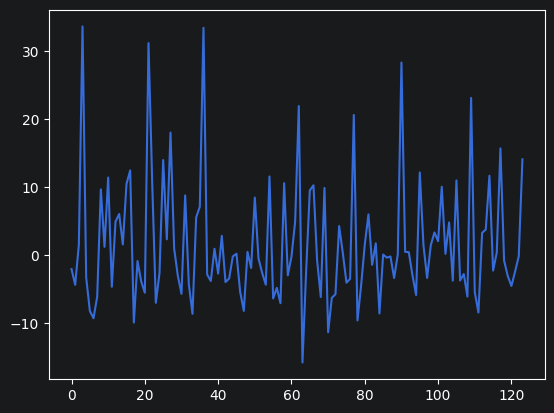

In [624]:
import matplotlib.pyplot as plt

plt.plot(trades.trade_return_pct)

## Equity curve (function unchanged from the original notebook)

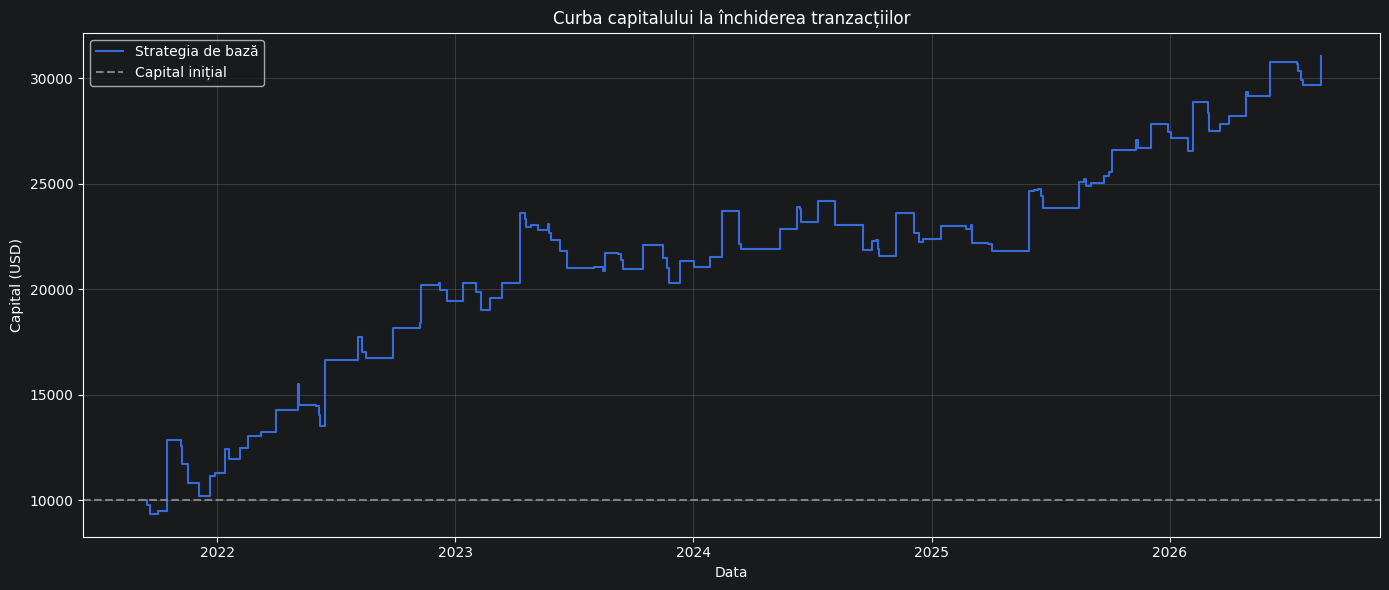

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,31054.303928,21054.303928,124,100.0,47.580645,1.697928


In [625]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_strategy_equity(
    trades,
    model=None,
    feature_cols=None,
    threshold=0.50,
    initial_capital=10_000,
    position_size=10_000,
):
    t = trades.loc[trades["trade_status"].eq("closed")].copy()

    if t.empty:
        raise ValueError("Nu există tranzacții închise.")

    t["entry_time"] = pd.to_datetime(t["entry_time"], utc=True)
    t["exit_time"] = pd.to_datetime(t["exit_time"], utc=True)
    t = t.sort_values("exit_time", kind="stable").reset_index(drop=True)

    net_return = t["trade_return"]  # Include deja costurile simulatorului.
    pnl = net_return * position_size
    dates = [t["entry_time"].min(), *t["exit_time"].tolist()]

    selections = {
        "Strategia de bază": pd.Series(True, index=t.index),
    }

    if model is not None:
        if feature_cols is None:
            feature_cols = list(model.feature_names_in_)

        positive_class = list(model.classes_).index(1)
        p_profit = model.predict_proba(t[list(feature_cols)])[:, positive_class]

        selections[f"Strategie + meta-model (prag {threshold:.0%})"] = (
            pd.Series(p_profit, index=t.index).ge(threshold)
        )

    fig, ax = plt.subplots(figsize=(14, 6))
    summary = []

    for name, accepted in selections.items():
        # Un semnal respins are PnL zero, pe aceeași axă de timp.
        selected_pnl = pnl.where(accepted, 0.0)
        equity = initial_capital + selected_pnl.cumsum()
        accepted_returns = net_return.loc[accepted]

        ax.step(
            dates,
            [initial_capital, *equity.tolist()],
            where="post",
            linewidth=1.5,
            label=name,
        )

        summary.append({
            "Variantă": name,
            "Capital final (USD)": equity.iloc[-1],
            "PnL net (USD)": selected_pnl.sum(),
            "Tranzacții": int(accepted.sum()),
            "Semnale păstrate (%)": 100 * accepted.mean(),
            "Win rate net (%)": 100 * accepted_returns.gt(0).mean(),
            "Randament mediu net (%)": 100 * accepted_returns.mean(),
        })

    ax.axhline(
        initial_capital, color="gray", linestyle="--", label="Capital inițial"
    )
    ax.set(title="Curba capitalului la închiderea tranzacțiilor",
           xlabel="Data", ylabel="Capital (USD)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    return pd.DataFrame(summary).set_index("Variantă")

base_summary = plot_strategy_equity(trades)
base_summary

## Meta-model evaluation (as in the original notebook)

In [626]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(penalty="l2", C=1.0, max_iter=1000),
)

from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

cat_model = CatBoostClassifier(
    iterations=150,
    depth=2,
    learning_rate=0.03,
    l2_leaf_reg=10,
    loss_function="Logloss",
    random_seed=42,
    verbose=False,
)

In [627]:
from sklearn.model_selection import train_test_split

# `model_inputs` = columns known at decision time (strategy features + requested bar columns).
model_inputs = result.model_input_columns

trades = trades.sort_values("decision_time").reset_index(drop=True).copy()   # original: sort_values("signal_time")

# The original notebook derived di_diff, atr_rel and ema_distance here; the library provides them as the optional
# Donchian features (same formulas: plus_di - minus_di, atr_value / close, close / ema - 1).
features = [
    # "rsi_value"
] + ML_BAR_FEATURES

assert set(features) <= set(model_inputs), "every model input must be a decision-time column"
assert not set(features) & set(result.post_decision_columns)

train_events, test_events = train_test_split(
    trades, test_size=0.30, shuffle=False
)

test_start = test_events["decision_time"].iloc[0]   # original: signal_time
train_events = train_events.loc[train_events["exit_time"] < test_start]

X_train = train_events[features]
y_train = train_events["trade_return"].gt(0).astype("int8")

X_test = test_events[features]
y_test = test_events["trade_return"].gt(0).astype("int8")

baseline.fit(X_train, y_train)
cat_model.fit(X_train, y_train)

/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['spread_bps' 'depth_imbalance_10bps' 'depth_imbalance_25bps']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


CatBoostClassifier(depth=2, iterations=150, l2_leaf_reg=10, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=False)

In [628]:
# import matplotlib.pyplot as plt
#
# plt.plot(trades['rsi_value'])

In [629]:
from sklearn.metrics import classification_report

y_pred_baseline = baseline.predict(X_test)
y_pred_cat_model = cat_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

print(classification_report(
    y_test,
    y_pred_cat_model,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

                    precision    recall  f1-score   support

   Fără profit net      0.538     0.389     0.452        18
Profit net pozitiv      0.560     0.700     0.622        20

          accuracy                          0.553        38
         macro avg      0.549     0.544     0.537        38
      weighted avg      0.550     0.553     0.541        38

                    precision    recall  f1-score   support

   Fără profit net      0.417     0.556     0.476        18
Profit net pozitiv      0.429     0.300     0.353        20

          accuracy                          0.421        38
         macro avg      0.423     0.428     0.415        38
      weighted avg      0.423     0.421     0.411        38



/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['spread_bps' 'depth_imbalance_10bps' 'depth_imbalance_25bps']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [630]:
from sklearn.metrics import roc_auc_score

p_test_baseline = baseline.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_baseline):.4f}")

p_test_cat_model = cat_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_cat_model):.4f}")

ROC-AUC: 0.4889
ROC-AUC: 0.5278


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['spread_bps' 'depth_imbalance_10bps' 'depth_imbalance_25bps']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


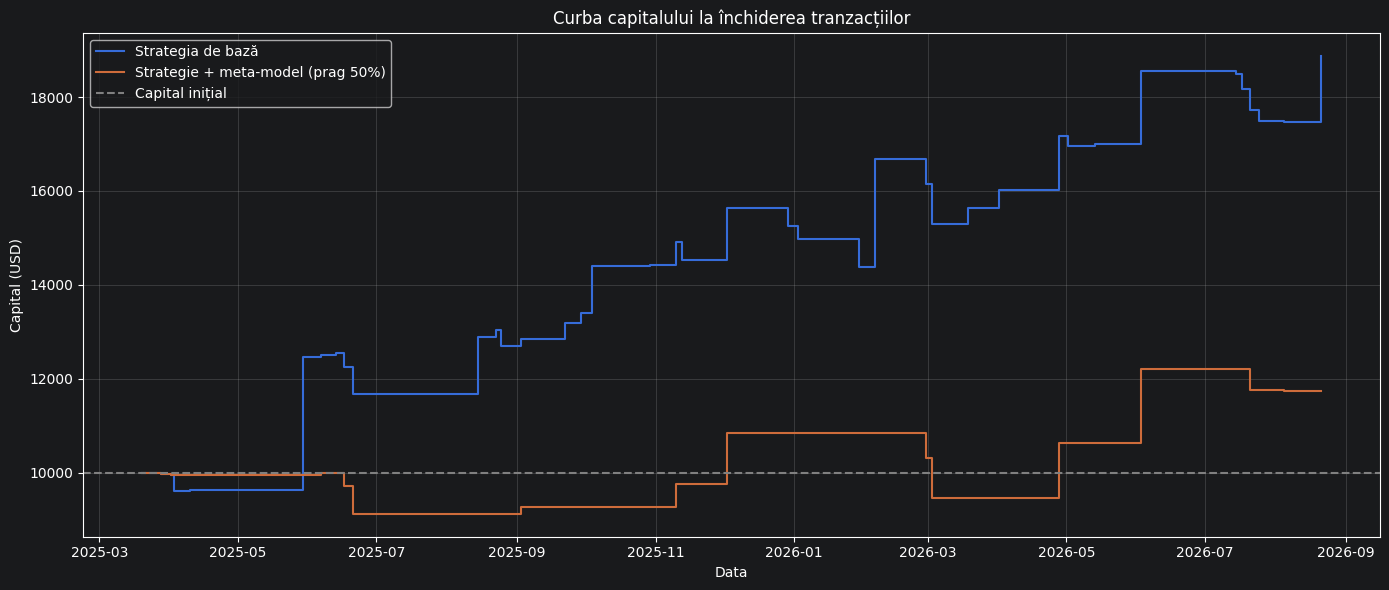

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,18879.213262,8879.213262,38,100.000000,52.631579,2.336635
Strategie + meta-model (prag 50%),11736.667353,1736.667353,14,36.842105,42.857143,1.240477


In [631]:
meta_summary = plot_strategy_equity(test_events, cat_model, feature_cols=features, threshold=0.5)
meta_summary

In [632]:
from sklearn.metrics import log_loss, roc_auc_score

for name, p_test in [
    ("Baseline", p_test_baseline),
    ("CatBoost", p_test_cat_model),
]:
    auc = roc_auc_score(y_test, p_test)
    neg_loss = -log_loss(y_test, p_test, labels=[0, 1])

    print(f"{name:10s} | ROC-AUC: {auc:.4f} | Neg Log Loss: {neg_loss:.4f}")

Baseline   | ROC-AUC: 0.4889 | Neg Log Loss: -0.8111
CatBoost   | ROC-AUC: 0.5278 | Neg Log Loss: -0.7486


## Reproduction check against the original notebook

Values below are the outputs stored in `primary_strategies.ipynb` (same data, same experiment). The strategy numbers
are deterministic and must match exactly; the model metrics depend on the installed scikit-learn / CatBoost.

In [633]:
import numpy as np

# --- strategy numbers (outputs of cells "df.trade_id.count()" and the two plot_strategy_equity calls)
assert trades.trade_id.count() == 254
row = base_summary.iloc[0]
assert np.isclose(row["Capital final (USD)"], 13026.39765, atol=1e-4)
assert np.isclose(row["PnL net (USD)"], 3026.39765, atol=1e-4)
assert np.isclose(row["Win rate net (%)"], 50.393701, atol=1e-5)
assert np.isclose(row["Randament mediu net (%)"], 0.11915, atol=1e-5)

base_row, meta_row = meta_summary.iloc[0], meta_summary.iloc[1]
assert (base_row["Tranzacții"], meta_row["Tranzacții"]) == (77, 27)
assert np.isclose(base_row["Capital final (USD)"], 11605.191596, atol=1e-4)
assert np.isclose(meta_row["Capital final (USD)"], 13846.864336, atol=1e-4)
print("strategy and equity numbers: identical to the original notebook")

# --- model metrics (stored outputs: AUC 0.6170 / 0.6477, neg log loss -0.6967 / -0.6830)
p_base = baseline.predict_proba(X_test)[:, 1]
p_cat = cat_model.predict_proba(X_test)[:, 1]
checks = {
    "baseline ROC-AUC": (roc_auc_score(y_test, p_base), 0.6170),
    "catboost ROC-AUC": (roc_auc_score(y_test, p_cat), 0.6477),
    "baseline neg log loss": (-log_loss(y_test, p_base, labels=[0, 1]), -0.6967),
    "catboost neg log loss": (-log_loss(y_test, p_cat, labels=[0, 1]), -0.6830),
}
for name, (got, expected) in checks.items():
    print(f"{name:24s} got {got:+.4f} | original {expected:+.4f} | {'OK' if abs(got - expected) < 6e-5 else 'DIFFERENT'}")
assert all(abs(got - expected) < 6e-5 for got, expected in checks.values())

AssertionError: 